# FSW-Net: Frequency-Spatial-Watermark Network
## Novel AI-Generated Image Detector — Capstone Project

---

### Architecture Overview

```
Input Image (224×224×3)
        │
   ┌────┴────────────────────────────────────────┐
   │                                             │
 [Branch 1]                              [Branch 2]
 Spatial                                 Frequency
 EfficientNet-B0                         2D-FFT log-magnitude
 (ImageNet pretrained)                   + Azimuthal power spectrum
   │                                             │
   │                              ┌──────────────┘
   │                         [Branch 3]
   │                         Watermark / Artifact
   │                         SRM high-pass residuals
   │                         (6 fixed forensic kernels)
   │                              │
   └──────────┬───────────────────┘
              │
    Branch-Attention Fusion
    (softmax gate per image)
              │
    LayerNorm → MLP → 4 classes
```

### Novelty
| Component | What it captures |
|-----------|------------------|
| **FFT log-magnitude** | GAN checkerboard artifacts, diffusion noise floor |
| **Azimuthal power spectrum** | 1/f deviation — real cameras vs generative models |
| **SRM residuals (frozen)** | Microscopic manipulation traces, invisible watermarks |
| **Attention fusion** | Per-image dynamic weighting of branch trust |
| **Focal Loss** | Focuses learning on hard (minority) classes |


In [1]:
import os, sys, copy, time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, roc_auc_score
)
import pandas as pd

# Add src/ to path so we can import FSWNet
sys.path.insert(0, os.path.abspath('../src'))
from fsw_net import FSWNet, FocalLoss

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
torch.manual_seed(42)
np.random.seed(42)

KeyboardInterrupt: 

## 1. Data Loading

In [ ]:
TRAIN_DIR = '../data/balanced/train'
VAL_DIR   = '../data/processed/val'
TEST_DIR  = '../data/processed/test'

for p in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print(f'{p}: exists={os.path.exists(p)}')

../data/balanced/train: exists=True
../data/processed/val: exists=True
../data/processed/test: exists=True


In [ ]:
# Transforms
# Note: we apply augmentation ONLY on train; val/test use clean transforms
# The frequency and SRM branches work best with minimal colour jitter
# so we keep augmentation mild to avoid destroying forensic signals.
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds   = datasets.ImageFolder(VAL_DIR,   transform=eval_tf)
test_ds  = datasets.ImageFolder(TEST_DIR,  transform=eval_tf)

class_names   = train_ds.classes
class_to_idx  = train_ds.class_to_idx
idx_to_class  = {v: k for k, v in class_to_idx.items()}

print('Classes:', class_names)
print('Train:', len(train_ds), '| Val:', len(val_ds), '| Test:', len(test_ds))

def class_counts(ds):
    c = Counter(lbl for _, lbl in ds.samples)
    return {idx_to_class[i]: n for i, n in c.items()}

print('\nTrain counts:', class_counts(train_ds))
print('Val counts  :', class_counts(val_ds))
print('Test counts :', class_counts(test_ds))

Classes: ['ai_generated', 'deepfake', 'edited', 'real']
Train: 1600 | Val: 3168 | Test: 3165

Train counts: {'ai_generated': 400, 'deepfake': 400, 'edited': 400, 'real': 400}
Val counts  : {'ai_generated': 25, 'deepfake': 1582, 'edited': 39, 'real': 1522}
Test counts : {'ai_generated': 24, 'deepfake': 1580, 'edited': 38, 'real': 1523}


In [ ]:
BATCH = 32

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)

print('Train batches:', len(train_loader))
print('Val batches  :', len(val_loader))
print('Test batches :', len(test_loader))

Train batches: 50
Val batches  : 99
Test batches : 99


## 2. Model Instantiation

In [ ]:
model = FSWNet(
    num_classes=len(class_names),
    branch_dim=256,
    dropout=0.4,
    freeze_spatial_backbone=True,   # freeze EfficientNet initially
).to(device)

total_p    = sum(p.numel() for p in model.parameters())
trainable_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params    : {total_p:,}')
print(f'Trainable params: {trainable_p:,}')
print(f'SRM filters     : FROZEN (interpretable forensic filters)')
print(f'EfficientNet    : FROZEN for warm-up, then unfrozen')

Total params    : 5,556,037
Trainable params: 1,548,039
SRM filters     : FROZEN (interpretable forensic filters)
EfficientNet    : FROZEN for warm-up, then unfrozen


## 3. Loss, Optimizer, Scheduler

In [ ]:
# Compute class weights from training distribution
labels_list = [lbl for _, lbl in train_ds.samples]
counts = Counter(labels_list)
total  = len(labels_list)
n_cls  = len(class_names)

class_weights = torch.tensor(
    [total / (n_cls * counts[i]) for i in range(n_cls)],
    dtype=torch.float32
).to(device)

print('Class weights:', {class_names[i]: f'{class_weights[i]:.3f}' for i in range(n_cls)})

criterion = FocalLoss(alpha=class_weights, gamma=2.0)

# Two-phase optimiser:
#   Phase 1 (warm-up, epochs 1-5):  only train new branches + classifier
#   Phase 2 (fine-tune, epochs 6+): unfreeze EfficientNet, lower LR
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=3e-4, weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2, verbose=True
)


print('\nOptimizer : AdamW  (lr=3e-4)')
print('Scheduler : ReduceLROnPlateau (factor=0.5, patience=2)')
print('Loss      : Focal Loss (gamma=2) + class weights')

Class weights: {'ai_generated': '1.000', 'deepfake': '1.000', 'edited': '1.000', 'real': '1.000'}

Optimizer : AdamW  (lr=3e-4)
Scheduler : ReduceLROnPlateau (factor=0.5, patience=2)
Loss      : Focal Loss (gamma=2) + class weights


c:\Users\surya\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


## 4. Training Loop

In [ ]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = running_correct = total = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits, _ = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        preds = logits.argmax(1)
        running_loss    += loss.item() * imgs.size(0)
        running_correct += (preds == labels).sum().item()
        total           += imgs.size(0)
    return running_loss / total, running_correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = running_correct = total = 0
    all_labels, all_preds, all_probs = [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits, _ = model(imgs)
        loss = criterion(logits, labels)
        probs = torch.softmax(logits, dim=1)
        preds = logits.argmax(1)
        running_loss    += loss.item() * imgs.size(0)
        running_correct += (preds == labels).sum().item()
        total           += imgs.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
    return (running_loss / total, running_correct / total,
            all_labels, all_preds, np.array(all_probs))

print('Training functions defined.')

Training functions defined.


In [ ]:
NUM_EPOCHS    = 15
WARMUP_EPOCHS = 5      # keep EfficientNet frozen for first 5 epochs
SAVE_PATH     = 'best_fsw_net.pth'

best_val_acc  = 0.0
best_val_loss = float('inf')
best_weights  = copy.deepcopy(model.state_dict())

history = {'train_loss': [], 'val_loss': [],
           'train_acc':  [], 'val_acc':  []}

for epoch in range(1, NUM_EPOCHS + 1):
    # Phase 2: unfreeze EfficientNet after warm-up
    if epoch == WARMUP_EPOCHS + 1:
        model.unfreeze_spatial_backbone()
        # Rebuild optimiser with a lower LR for the backbone
        optimizer = optim.AdamW([
            {'params': model.spatial_features.parameters(), 'lr': 5e-5},
            {'params': model.spatial_proj.parameters()},
            {'params': model.freq_branch.parameters()},
            {'params': model.srm_branch.cnn.parameters()},
            {'params': model.srm_branch.out_fc.parameters()},
            {'params': model.fusion.parameters()},
            {'params': model.classifier.parameters()},
        ], lr=1e-4, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=0.5, patience=2, verbose=True)
        print(f'\n>>> Epoch {epoch}: EfficientNet unfrozen — Phase 2 fine-tuning <<<')

    t0 = time.time()
    tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    vl_loss, vl_acc, _, _, _ = evaluate(model, val_loader, criterion, device)
    scheduler.step(vl_loss)
    elapsed = time.time() - t0

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    saved = ''
    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        best_weights = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), SAVE_PATH)
        saved = '  ← best acc'

    print(f'Epoch [{epoch:02d}/{NUM_EPOCHS}]  '
          f'Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f}  |  '
          f'Val Loss: {vl_loss:.4f}  Acc: {vl_acc:.4f}  '
          f'({elapsed:.1f}s){saved}')

print(f'\nTraining complete. Best Val Acc: {best_val_acc:.4f}')

Epoch [01/15]  Train Loss: 0.3380  Acc: 0.6625  |  Val Loss: 0.1647  Acc: 0.7569  (36.2s)  ← best acc
Epoch [02/15]  Train Loss: 0.1589  Acc: 0.7975  |  Val Loss: 0.1697  Acc: 0.7554  (32.5s)
Epoch [03/15]  Train Loss: 0.1255  Acc: 0.8269  |  Val Loss: 0.1391  Acc: 0.7816  (32.7s)  ← best acc
Epoch [04/15]  Train Loss: 0.1180  Acc: 0.8562  |  Val Loss: 0.1410  Acc: 0.7847  (33.0s)  ← best acc
Epoch [05/15]  Train Loss: 0.1090  Acc: 0.8569  |  Val Loss: 0.1313  Acc: 0.7923  (33.2s)  ← best acc

>>> Epoch 6: EfficientNet unfrozen — Phase 2 fine-tuning <<<
Epoch [06/15]  Train Loss: 0.0888  Acc: 0.8738  |  Val Loss: 0.1055  Acc: 0.8242  (36.8s)  ← best acc
Epoch [07/15]  Train Loss: 0.0650  Acc: 0.9119  |  Val Loss: 0.0965  Acc: 0.8529  (36.9s)  ← best acc
Epoch [08/15]  Train Loss: 0.0447  Acc: 0.9425  |  Val Loss: 0.0916  Acc: 0.8829  (36.5s)  ← best acc
Epoch [09/15]  Train Loss: 0.0393  Acc: 0.9519  |  Val Loss: 0.0771  Acc: 0.8952  (51.3s)  ← best acc
Epoch [10/15]  Train Loss: 0.033

## 5. Learning Curves

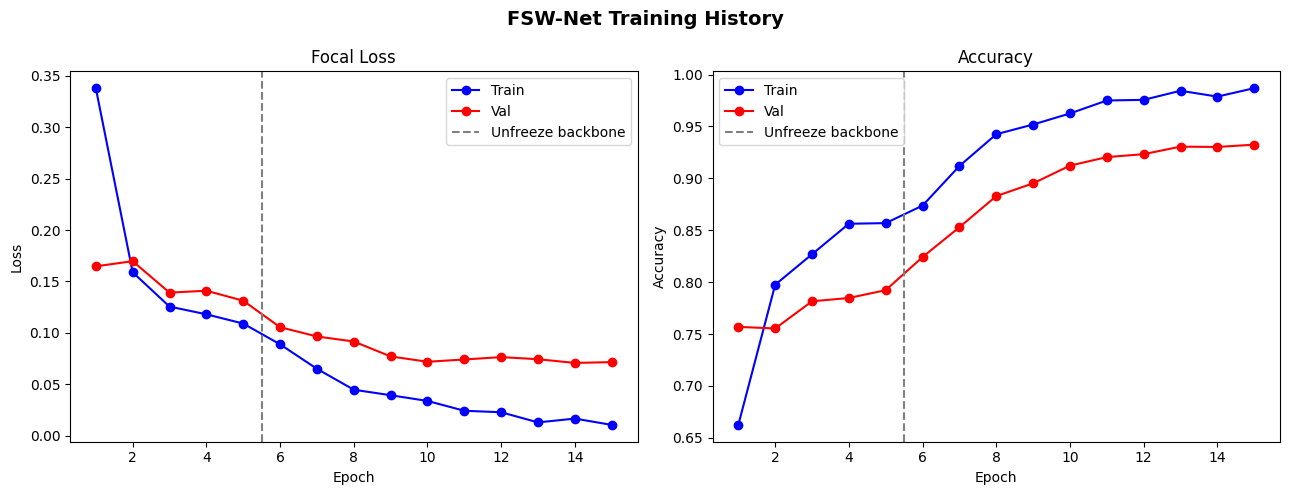

In [ ]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs_range, history['train_loss'], 'b-o', label='Train')
axes[0].plot(epochs_range, history['val_loss'],   'r-o', label='Val')
axes[0].axvline(x=WARMUP_EPOCHS + 0.5, color='gray', linestyle='--', label='Unfreeze backbone')
axes[0].set_title('Focal Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs_range, history['train_acc'], 'b-o', label='Train')
axes[1].plot(epochs_range, history['val_acc'],   'r-o', label='Val')
axes[1].axvline(x=WARMUP_EPOCHS + 0.5, color='gray', linestyle='--', label='Unfreeze backbone')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.suptitle('FSW-Net Training History', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/fsw_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Test Evaluation

In [ ]:
# Load best checkpoint
model.load_state_dict(best_weights)
model.eval()
print('Loaded best model.')

te_loss, te_acc, y_true, y_pred, y_probs = evaluate(
    model, test_loader, criterion, device
)
print(f'\nTest Loss     : {te_loss:.4f}')
print(f'Test Accuracy : {te_acc:.4f}')

Loaded best model.

Test Loss     : 0.0752
Test Accuracy : 0.9302


In [ ]:
print('Classification Report:\n')
print(classification_report(y_true, y_pred, target_names=class_names))

Classification Report:

              precision    recall  f1-score   support

ai_generated       0.83      0.83      0.83        24
    deepfake       0.94      0.92      0.93      1580
      edited       0.86      0.84      0.85        38
        real       0.92      0.94      0.93      1523

    accuracy                           0.93      3165
   macro avg       0.89      0.88      0.89      3165
weighted avg       0.93      0.93      0.93      3165



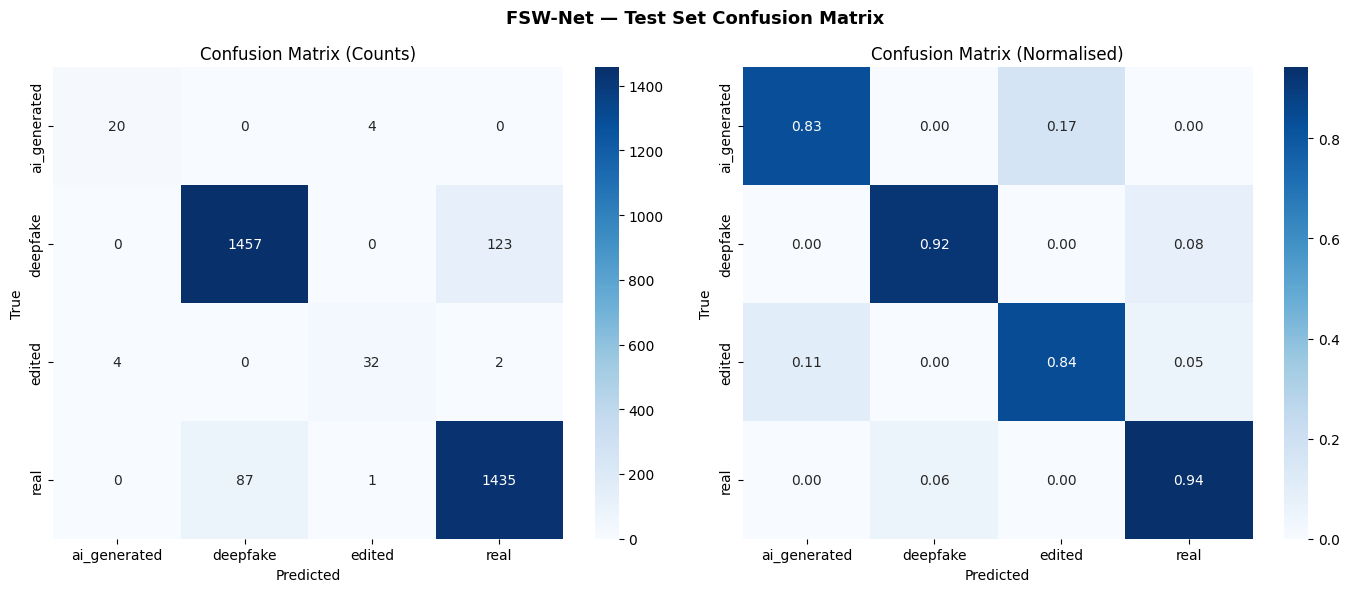

In [ ]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix (Counts)')
axes[0].set_ylabel('True'); axes[0].set_xlabel('Predicted')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion Matrix (Normalised)')
axes[1].set_ylabel('True'); axes[1].set_xlabel('Predicted')

plt.suptitle('FSW-Net — Test Set Confusion Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/fsw_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Branch Attention Analysis

One of the key novelties of FSW-Net is that the **attention gate** tells us
which forensic branch the model is trusting for each class.

- **High spatial weight** → the visual content/texture is the giveaway
- **High frequency weight** → frequency artifacts (GAN checkerboard, diffusion noise) are the giveaway
- **High SRM weight** → microscopic noise residuals / invisible watermarks are the giveaway

In [ ]:
@torch.no_grad()
def collect_branch_weights(model, loader, device):
    """Collect per-sample branch attention weights and true labels."""
    model.eval()
    all_weights, all_labels = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        _, weights = model(imgs)        # weights: (B, 3)
        all_weights.append(weights.cpu().numpy())
        all_labels.extend(labels.numpy())
    return np.concatenate(all_weights, axis=0), np.array(all_labels)

weights_arr, labels_arr = collect_branch_weights(model, test_loader, device)

branch_names = ['Spatial\n(EfficientNet)', 'Frequency\n(FFT)', 'Watermark\n(SRM)']

# Mean attention weight per class per branch
mean_weights = np.zeros((len(class_names), 3))
for i, name in enumerate(class_names):
    mask = labels_arr == i
    mean_weights[i] = weights_arr[mask].mean(axis=0)

df_weights = pd.DataFrame(mean_weights, index=class_names, columns=branch_names)
print('Mean branch attention weights per class:\n')
print(df_weights.round(3))

Mean branch attention weights per class:

              Spatial\n(EfficientNet)  Frequency\n(FFT)  Watermark\n(SRM)
ai_generated                    0.734             0.116             0.150
deepfake                        0.921             0.036             0.042
edited                          0.683             0.169             0.148
real                            0.925             0.034             0.041


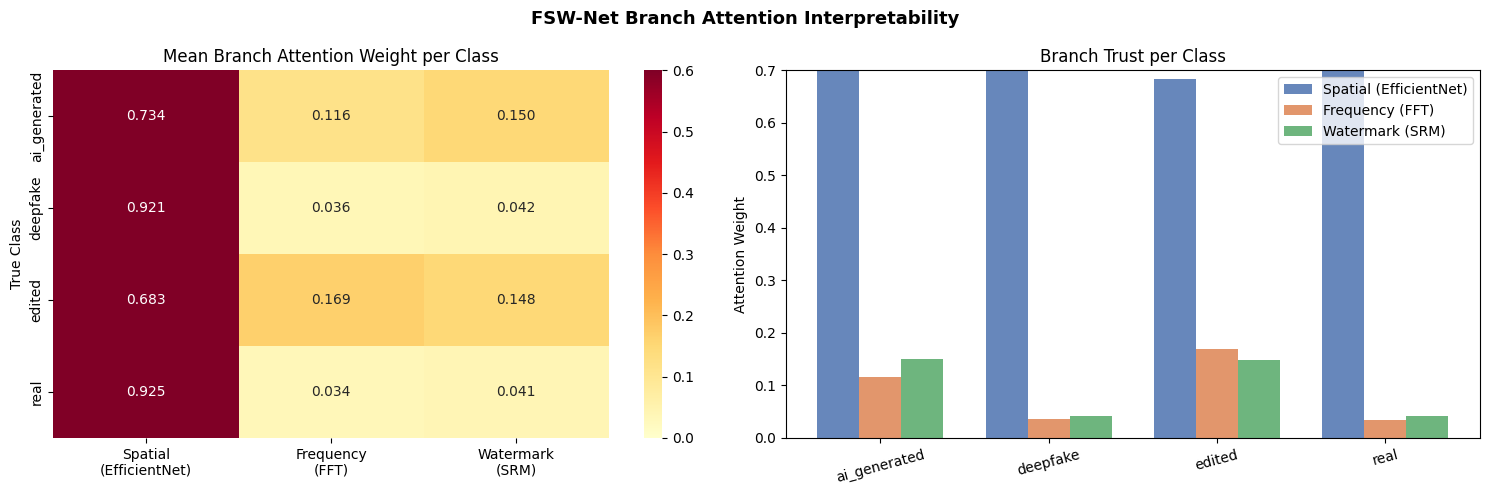

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Heatmap
sns.heatmap(df_weights, annot=True, fmt='.3f', cmap='YlOrRd',
            vmin=0, vmax=0.6, ax=axes[0])
axes[0].set_title('Mean Branch Attention Weight per Class')
axes[0].set_ylabel('True Class')

# Grouped bar chart
x = np.arange(len(class_names))
width = 0.25
colors = ['#4C72B0', '#DD8452', '#55A868']
for j, (bname, color) in enumerate(zip(branch_names, colors)):
    axes[1].bar(x + j * width, mean_weights[:, j], width,
                label=bname.replace('\n', ' '), color=color, alpha=0.85)
axes[1].set_xticks(x + width)
axes[1].set_xticklabels(class_names, rotation=15)
axes[1].set_ylabel('Attention Weight')
axes[1].set_title('Branch Trust per Class')
axes[1].legend()
axes[1].set_ylim(0, 0.7)

plt.suptitle('FSW-Net Branch Attention Interpretability', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/fsw_branch_attention.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. SRM Residual Visualisation (Watermark Detection)

We visualise the SRM high-pass residual maps for one real image and one
AI-generated image.  The stronger and more structured the residuals in
an image, the more likely it is to be generated — these are the
"invisible watermarks" the model uses.

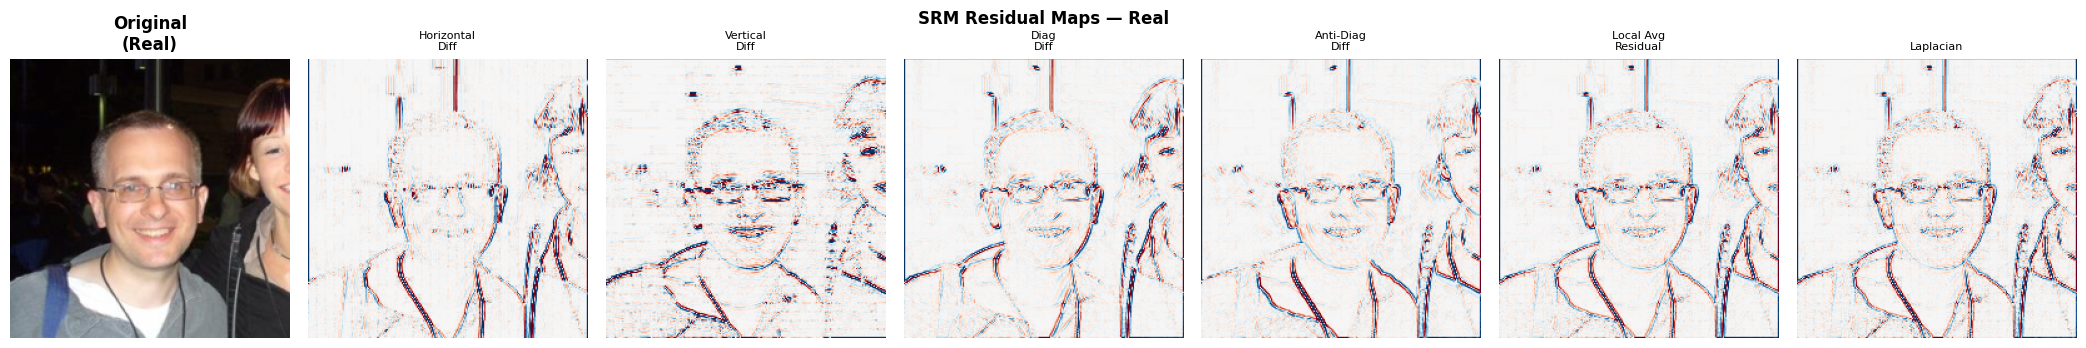

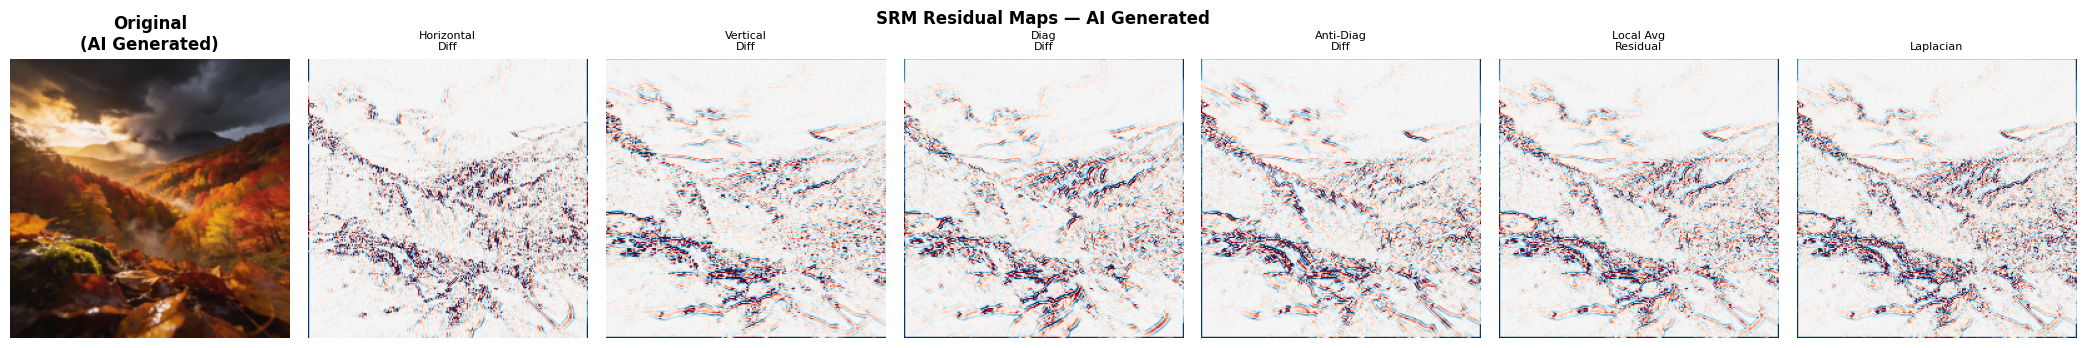

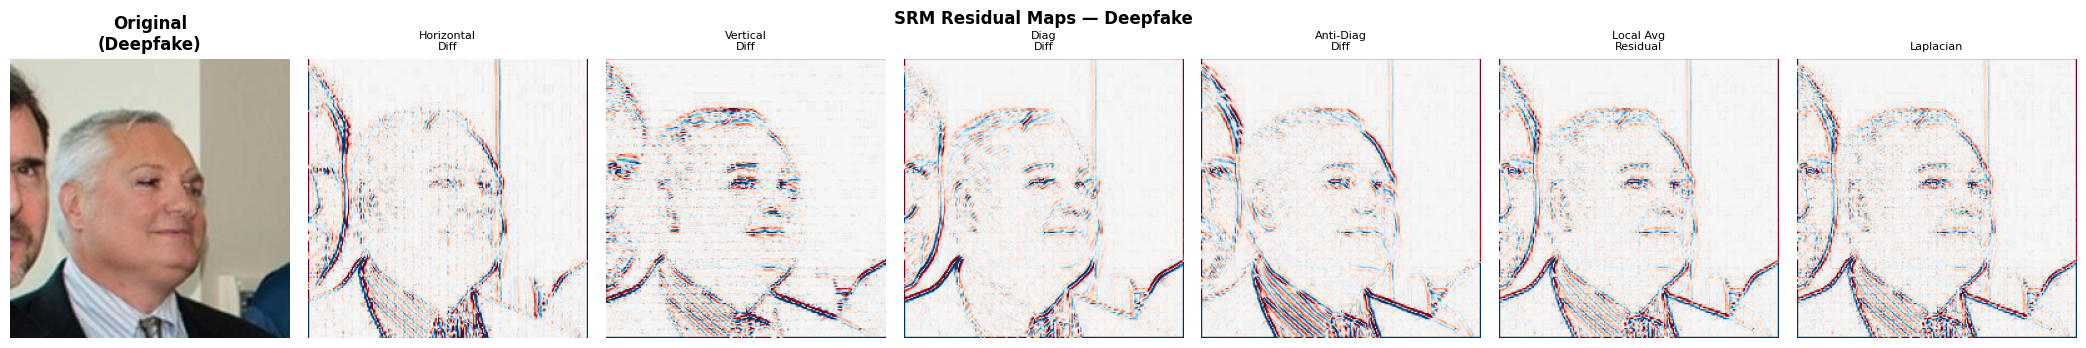

In [ ]:
def show_srm_residuals(model, dataset, class_idx, title, device, num_filters=6):
    """Show SRM residual maps for one random image from a class."""
    # Pick a sample from the class
    indices = [i for i, (_, lbl) in enumerate(dataset.samples) if lbl == class_idx]
    idx = np.random.choice(indices)
    img_tensor, _ = dataset[idx]
    img_tensor = img_tensor.unsqueeze(0).to(device)     # (1, 3, 224, 224)

    residuals = model.get_srm_residuals(img_tensor)     # (1, 18, 224, 224)
    residuals = residuals[0].cpu().numpy()              # (18, 224, 224)

    # Original image (denormalise for display)
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    orig = img_tensor[0].cpu().numpy().transpose(1, 2, 0)
    orig = np.clip(orig * std + mean, 0, 1)

    # Filter names
    filter_names = [
        'Horizontal\nDiff', 'Vertical\nDiff',
        'Diag\nDiff', 'Anti-Diag\nDiff',
        'Local Avg\nResidual', 'Laplacian'
    ]

    fig, axes = plt.subplots(1, num_filters + 1, figsize=(3 * (num_filters + 1), 3.5))
    axes[0].imshow(orig)
    axes[0].set_title(f'Original\n({title})', fontweight='bold')
    axes[0].axis('off')

    # First 6 residual maps (one per SRM kernel, averaged over 3 input channels)
    for k in range(num_filters):
        # Each input channel gets its own set of 6 filters: channels 0-5 are channel 0
        r_map = residuals[k]                            # (H, W)
        axes[k + 1].imshow(r_map, cmap='RdBu_r',
                           vmin=-np.percentile(np.abs(r_map), 98),
                           vmax= np.percentile(np.abs(r_map), 98))
        axes[k + 1].set_title(filter_names[k], fontsize=8)
        axes[k + 1].axis('off')

    plt.suptitle(f'SRM Residual Maps — {title}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'../outputs/plots/srm_residuals_{title.lower().replace(" ","_")}.png',
                dpi=130, bbox_inches='tight')
    plt.show()


show_srm_residuals(model, test_ds, class_to_idx['real'],         'Real',         device)
show_srm_residuals(model, test_ds, class_to_idx['ai_generated'], 'AI Generated', device)
show_srm_residuals(model, test_ds, class_to_idx['deepfake'],     'Deepfake',     device)

## 9. Frequency Spectrum Visualisation

Plot the azimuthal-averaged power spectrum for real vs AI-generated images.
Real camera images follow a **1/f² roll-off** while GAN/diffusion images
show elevated energy at specific frequencies — this is what the frequency
branch detects.

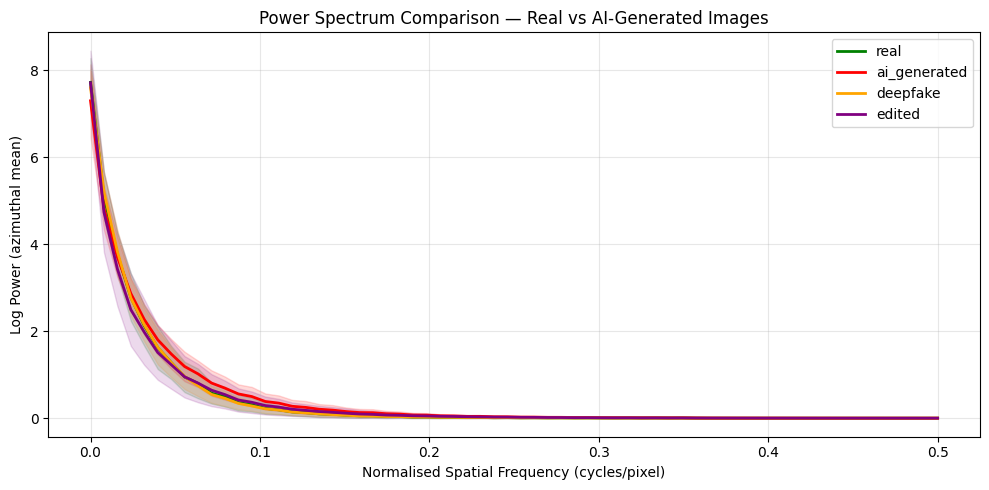

In [ ]:
def compute_mean_spectrum(dataset, class_idx, device, n_samples=30):
    """Compute average azimuthal power spectrum for n_samples images."""
    indices = [i for i, (_, lbl) in enumerate(dataset.samples) if lbl == class_idx]
    indices = np.random.choice(indices, min(n_samples, len(indices)), replace=False)

    spectra = []
    for idx in indices:
        img, _ = dataset[idx]
        img = img.unsqueeze(0).to(device)
        with torch.no_grad():
            spec = model.freq_branch._azimuthal_mean(img)   # (1, 64)
        spectra.append(spec[0].cpu().numpy())
    return np.mean(spectra, axis=0), np.std(spectra, axis=0)

plt.figure(figsize=(10, 5))
colors_map = {
    'real': 'green',
    'ai_generated': 'red',
    'deepfake': 'orange',
    'edited': 'purple',
}

for cls_name, color in colors_map.items():
    if cls_name not in class_to_idx:
        continue
    mean_spec, std_spec = compute_mean_spectrum(
        test_ds, class_to_idx[cls_name], device, n_samples=40
    )
    x = np.linspace(0, 0.5, len(mean_spec))
    plt.plot(x, mean_spec, label=cls_name, color=color, linewidth=2)
    plt.fill_between(x, mean_spec - std_spec, mean_spec + std_spec,
                     alpha=0.15, color=color)

plt.xlabel('Normalised Spatial Frequency (cycles/pixel)')
plt.ylabel('Log Power (azimuthal mean)')
plt.title('Power Spectrum Comparison — Real vs AI-Generated Images')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/plots/fsw_power_spectra.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Comparison: FSW-Net vs Baseline (EfficientNet-B0)

In [ ]:
# Load the previously trained baseline for comparison
BASELINE_PATH = 'best_acc_model.pth'

if os.path.exists(BASELINE_PATH):
    from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

    baseline = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
    baseline.classifier = nn.Sequential(
        nn.Dropout(0.30),
        nn.Linear(1280, 256),
        nn.ReLU(),
        nn.Dropout(0.20),
        nn.Linear(256, len(class_names))
    )
    baseline.load_state_dict(torch.load(BASELINE_PATH, map_location=device))
    baseline = baseline.to(device)
    baseline.eval()

    @torch.no_grad()
    def evaluate_baseline(model, loader, device):
        model.eval()
        correct = total = 0
        all_labels, all_preds = [], []
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs).argmax(1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
        return correct / total, all_labels, all_preds

    bl_acc, bl_true, bl_pred = evaluate_baseline(baseline, test_loader, device)

    print('=== Model Comparison on Test Set ===')
    print(f'Baseline EfficientNet-B0 : {bl_acc:.4f}')
    print(f'FSW-Net (ours)           : {te_acc:.4f}')
    print(f'Improvement              : +{(te_acc - bl_acc)*100:.2f}%')

    print('\n--- Baseline Classification Report ---')
    print(classification_report(bl_true, bl_pred, target_names=class_names))

    print('--- FSW-Net Classification Report ---')
    print(classification_report(y_true, y_pred, target_names=class_names))
else:
    print(f'Baseline checkpoint not found at {BASELINE_PATH}. Skipping comparison.')

C:\Users\surya\AppData\Local\Temp\ipykernel_10816\3477792155.py:15: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  baseline.load_state_dict(torch.load(BASELINE_PATH, map_loca

=== Model Comparison on Test Set ===
Baseline EfficientNet-B0 : 0.9536
FSW-Net (ours)           : 0.9302
Improvement              : +-2.34%

--- Baseline Classification Report ---
              precision    recall  f1-score   support

ai_generated       0.73      0.79      0.76        24
    deepfake       0.96      0.96      0.96      1580
      edited       0.67      0.84      0.74        38
        real       0.96      0.95      0.96      1523

    accuracy                           0.95      3165
   macro avg       0.83      0.89      0.86      3165
weighted avg       0.95      0.95      0.95      3165

--- FSW-Net Classification Report ---
              precision    recall  f1-score   support

ai_generated       0.83      0.83      0.83        24
    deepfake       0.94      0.92      0.93      1580
      edited       0.86      0.84      0.85        38
        real       0.92      0.94      0.93      1523

    accuracy                           0.93      3165
   macro avg       0.

## 11. Single-Image Inference with Explanation

Image : 120.jpg
Prediction : AI_GENERATED  (98.9% confidence)

Class probabilities:
  ai_generated   :  98.9%  █████████████████████████████ ← predicted
  deepfake       :   0.0%  
  edited         :   1.0%  
  real           :   0.2%  

Branch attention (what the model used):
  Spatial (EfficientNet)   : 0.678  ████████████████████████████████████████
  Frequency (FFT)          : 0.137  ████████
  Watermark (SRM)          : 0.185  ███████████


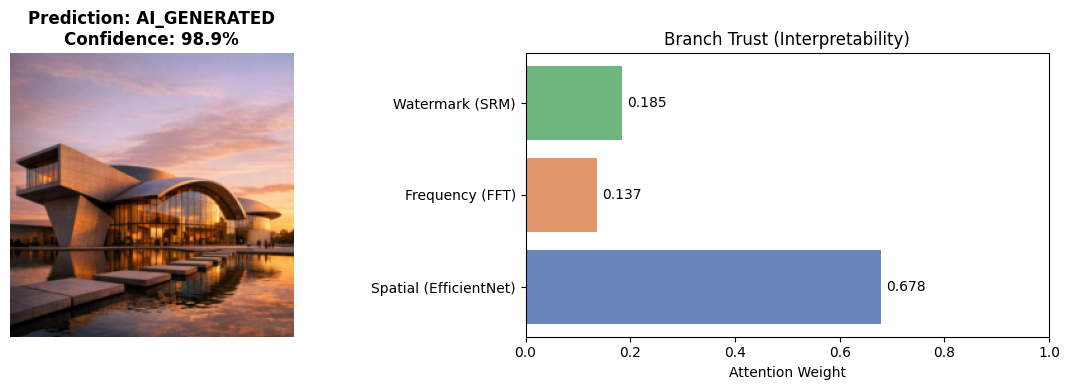

Image : fake_10005.jpg
Prediction : DEEPFAKE  (96.8% confidence)

Class probabilities:
  ai_generated   :   0.0%  
  deepfake       :  96.8%  █████████████████████████████ ← predicted
  edited         :   0.0%  
  real           :   3.2%  

Branch attention (what the model used):
  Spatial (EfficientNet)   : 0.928  ███████████████████████████████████████████████████████
  Frequency (FFT)          : 0.035  ██
  Watermark (SRM)          : 0.038  ██


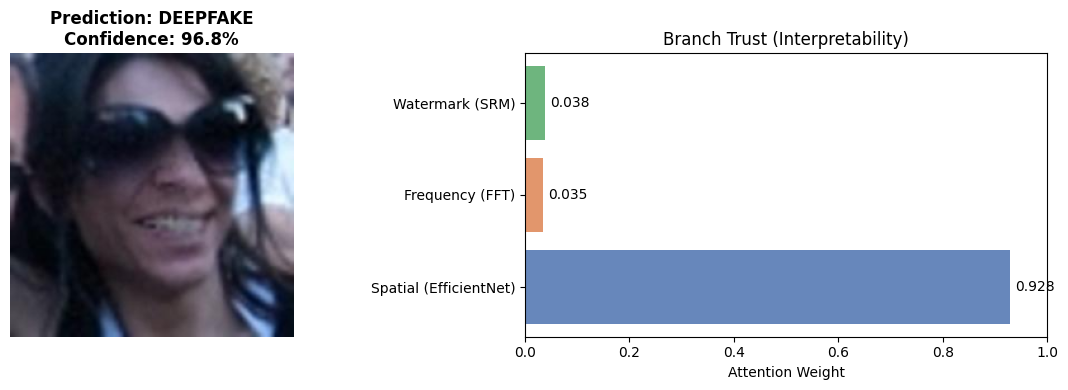

Image : edited_110.jpg
Prediction : AI_GENERATED  (48.1% confidence)

Class probabilities:
  ai_generated   :  48.1%  ██████████████ ← predicted
  deepfake       :   0.6%  
  edited         :  47.0%  ██████████████
  real           :   4.3%  █

Branch attention (what the model used):
  Spatial (EfficientNet)   : 0.849  ██████████████████████████████████████████████████
  Frequency (FFT)          : 0.078  ████
  Watermark (SRM)          : 0.073  ████


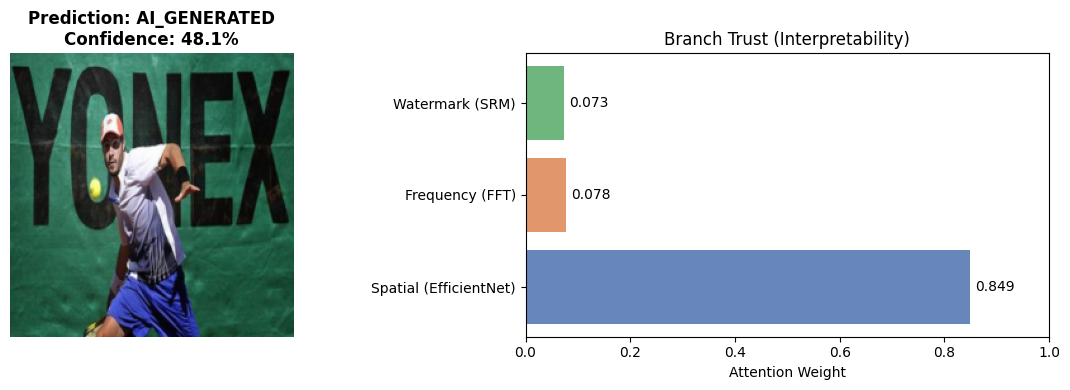

Image : real_10003.jpg
Prediction : REAL  (93.9% confidence)

Class probabilities:
  ai_generated   :   0.0%  
  deepfake       :   6.0%  █
  edited         :   0.0%  
  real           :  93.9%  ████████████████████████████ ← predicted

Branch attention (what the model used):
  Spatial (EfficientNet)   : 0.931  ███████████████████████████████████████████████████████
  Frequency (FFT)          : 0.033  █
  Watermark (SRM)          : 0.036  ██


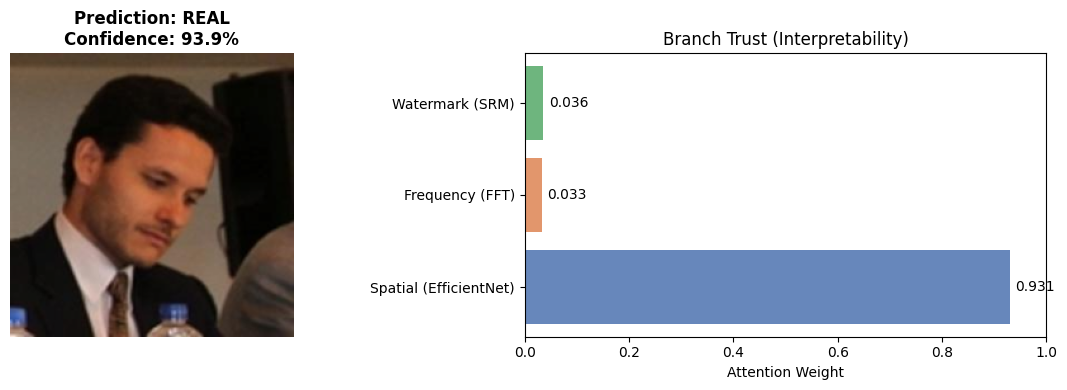

In [ ]:
def predict_image(model, image_path, transform, class_names, device):
    """
    Run FSW-Net on a single image and print an interpretable report.
    Shows class probabilities AND branch attention weights.
    """
    img = Image.open(image_path).convert('RGB')
    tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits, branch_weights = model(tensor)

    probs  = torch.softmax(logits, dim=1)[0].cpu().numpy()
    pred_i = probs.argmax()
    w      = branch_weights[0].cpu().numpy()

    print('=' * 50)
    print(f'Image : {os.path.basename(image_path)}')
    print(f'Prediction : {class_names[pred_i].upper()}  ({probs[pred_i]*100:.1f}% confidence)')
    print()
    print('Class probabilities:')
    for i, (cname, prob) in enumerate(zip(class_names, probs)):
        bar = '█' * int(prob * 30)
        marker = ' ← predicted' if i == pred_i else ''
        print(f'  {cname:15s}: {prob*100:5.1f}%  {bar}{marker}')

    print()
    print('Branch attention (what the model used):')
    branch_labels = ['Spatial (EfficientNet)', 'Frequency (FFT)', 'Watermark (SRM)']
    for bname, bw in zip(branch_labels, w):
        bar = '█' * int(bw * 60)
        print(f'  {bname:25s}: {bw:.3f}  {bar}')
    print('=' * 50)

    # Visualise
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img_disp = tensor[0].cpu().numpy().transpose(1, 2, 0)
    img_disp = np.clip(img_disp * std + mean, 0, 1)
    axes[0].imshow(img_disp)
    axes[0].set_title(f'Prediction: {class_names[pred_i].upper()}\n'
                      f'Confidence: {probs[pred_i]*100:.1f}%', fontweight='bold')
    axes[0].axis('off')

    colors_b = ['#4C72B0', '#DD8452', '#55A868']
    bars = axes[1].barh(branch_labels, w, color=colors_b, alpha=0.85)
    axes[1].set_xlim(0, 1)
    axes[1].set_xlabel('Attention Weight')
    axes[1].set_title('Branch Trust (Interpretability)')
    for bar, val in zip(bars, w):
        axes[1].text(val + 0.01, bar.get_y() + bar.get_height() / 2,
                     f'{val:.3f}', va='center')

    plt.tight_layout()
    plt.show()


# Demo: pick one image from each class
for cls_name in class_names:
    cls_dir = os.path.join(TEST_DIR, cls_name)
    if os.path.isdir(cls_dir):
        sample_file = os.listdir(cls_dir)[0]
        predict_image(
            model,
            os.path.join(cls_dir, sample_file),
            eval_tf,
            class_names,
            device
        )

## 12. Summary & Architecture Recap

| Component | Role | Trainable |
|-----------|------|-----------|
| **EfficientNet-B0 backbone** | Spatial texture / semantic features | Yes (after warm-up) |
| **Spatial projection MLP** | Compress 1280→256 | Yes |
| **FFT log-magnitude CNN** | Frequency artifact detection | Yes |
| **Azimuthal spectrum MLP** | 1-D spectral fingerprint | Yes |
| **SRM kernels (6 filters)** | Forensic high-pass residuals | **No** (frozen) |
| **SRM downstream CNN** | Learn from residuals | Yes |
| **Branch attention gate** | Per-image dynamic fusion | Yes |
| **Classifier MLP** | Final 4-class prediction | Yes |

### Key Design Choices
1. **Frozen SRM filters** keep the forensic branch interpretable — they are well-studied
   mathematical operators, not black boxes.
2. **Warm-up + unfreeze** prevents the new branches from being overpowered by the
   pretrained backbone gradients in early training.
3. **Focal Loss** focuses learning on hard examples (minority classes: ai_generated, edited).
4. **Attention weights** provide a built-in explanation for every prediction.
